# 05 — Delay minutes: a good metric, and can a model catch them?

**Goal.** The main model ranks incidents by their risk of becoming *major* (a safety
response or a delay of 30+ min). In its top 10% it catches about 38% of major incidents
but only about 16% of delay minutes. Two questions follow:

1. **Is delay minutes a good metric** for this data, or should the headline stay on
   safety and major incidents?
2. **Can a model aimed at minutes catch more of them?**

Everything here uses the cleaned data, the labels and the rolling backtest folds of
`code/modeling/` (train on the past, test on 2021, 2022 and 2023). The 2024-25 holdout
is not used.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import d2_tweedie_score

# The notebook lives in code/exploration/; the project modules live in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config
from cleaning.clean_incidents import DELAY_BUCKET_CEILINGS
from cleaning.load import load_incidents
from modeling.backtest import FOLDS, capture, run_backtest
from modeling.costs import delay_minutes
from modeling.features import MAIN_FEATURES, build_features
from modeling.target import add_targets, model_population

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Load train incidents and their delay minutes

Delay minutes are the **recorded delay** (end minus start) when it falls inside the
published delay bucket, and the bucket's lower bound otherwise (`costs.delay_minutes`,
`clean_incidents.py` step 7; documentation.md, Decision 9). Until Decision 9 they were
counted at the bucket's lower bound; section 2b compares the two. `before_holdout`
keeps 2019-2023 only.

In [2]:
labelled = add_targets(model_population(load_incidents()))
minutes = delay_minutes(labelled)
year = labelled["service_date"].dt.year
before_holdout = year <= 2023

print(f"Train incidents 2019-2023: {before_holdout.sum():,}   "
      f"delay minutes: {minutes[before_holdout].sum():,.0f}")

Train incidents 2019-2023: 21,058   delay minutes: 81,340


## 2. Is delay minutes a good metric?

### 2a. Where the minutes come from

Share of incidents and share of delay minutes in each delay bucket.

In [3]:
pre = labelled[before_holdout]
by_bucket = pd.DataFrame({
    "incidents": pre.groupby("delay_bucket", observed=True).size(),
    "minutes": minutes[before_holdout].groupby(pre["delay_bucket"], observed=True).sum(),
})
by_bucket["% of incidents"] = 100 * by_bucket["incidents"] / by_bucket["incidents"].sum()
by_bucket["% of minutes"] = 100 * by_bucket["minutes"] / by_bucket["minutes"].sum()
by_bucket.round(1)

,incidents,minutes,% of incidents,% of minutes
delay_bucket,,,,
02 min et moins,11845,6641.0,56.2,8.2
03 à 04 min,4657,15906.0,22.1,19.6
05 à 09 min,3145,19457.0,14.9,23.9
10 à 14 min,651,7441.0,3.1,9.1
15 à 19 min,206,3429.0,1.0,4.2
20 à 24 min,108,2342.0,0.5,2.9
25 à 29 min,78,2085.0,0.4,2.6
30 min et plus,368,24039.0,1.7,29.6


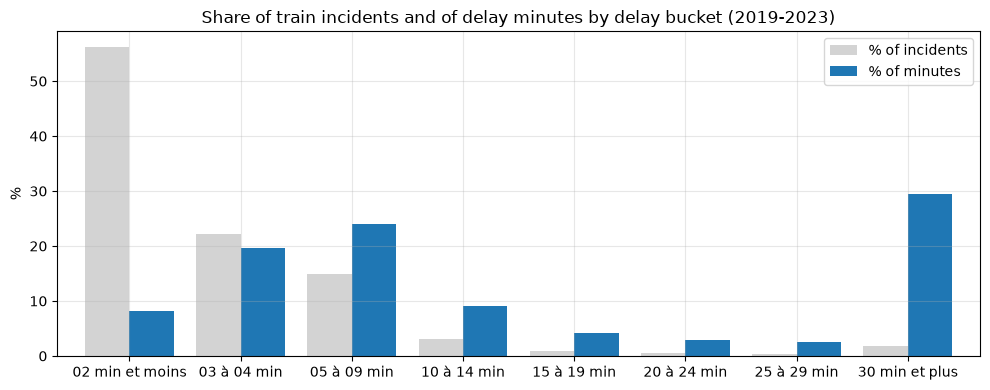

In [4]:
# Plot: share of incidents vs share of delay minutes, by delay bucket.
ax = by_bucket[["% of incidents", "% of minutes"]].plot.bar(
    color=["lightgray", "tab:blue"], width=0.8, figsize=(10, 4))
ax.set_title("Share of train incidents and of delay minutes by delay bucket (2019-2023)")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Finding.** The shortest bucket (2 min and less) is 56% of incidents but only about
8% of minutes. The 30+ bucket is under 2% of incidents but about 30% of minutes. The
3-4 and 5-9 min buckets, common and short, add up to about 44%.

### 2b. Recorded delay against the bucket, and what the old count missed

The data dictionary describes the start and end times as the start and end of the
delay for train incidents. If so, the recorded duration should fall inside the
published bucket. First: how often it does, by incident type. Then: the share of delay
minutes by severity tier under the old count (every incident at its bucket's lower
bound) and under the new one.

In [5]:
pre = labelled[before_holdout]
lower_bound = pre["delay_floor_minutes"].astype(float)
agrees = minutes[before_holdout] == pre["recorded_minutes"]

all_incidents = load_incidents()
station = all_incidents["incident_type"] == "S"
station_ceiling = all_incidents.loc[station, "delay_floor_minutes"].map(DELAY_BUCKET_CEILINGS)
station_agrees = all_incidents.loc[station, "recorded_minutes"].between(
    all_incidents.loc[station, "delay_floor_minutes"], station_ceiling)
thirty_plus = pre["delay_floor_minutes"] == 30
pd.Series({
    "train incidents: recorded delay inside the bucket (%)": 100 * agrees.mean(),
    "station incidents: recorded duration inside the bucket (%)": 100 * station_agrees.mean(),
    "30+ incidents: median recorded delay (min)": pre.loc[thirty_plus & agrees, "recorded_minutes"].median(),
    "30+ incidents: mean recorded delay (min)": pre.loc[thirty_plus & agrees, "recorded_minutes"].mean(),
    "minutes 2019-2023, old count (lower bound)": lower_bound.sum(),
    "minutes 2019-2023, new count": minutes[before_holdout].sum(),
}).round(1).to_frame("value")

,value
train incidents: recorded delay inside the bucket (%),98.0
station incidents: recorded duration inside the bucket (%),4.5
30+ incidents: median recorded delay (min),52.0
30+ incidents: mean recorded delay (min),65.4
"minutes 2019-2023, old count (lower bound)",54446.0
"minutes 2019-2023, new count",81340.0


In [6]:

def share_of_minutes(per_incident: pd.Series) -> pd.Series:
    # Share of 2019-2023 delay minutes by severity tier, in %.
    return 100 * per_incident.groupby(pre["severity_tier"], observed=True).sum() / per_incident.sum()


shares = pd.DataFrame({
    "old count (lower bound)": share_of_minutes(lower_bound),
    "new count (recorded delay)": share_of_minutes(minutes[before_holdout]),
})
shares.loc["major incidents (top two tiers)"] = shares.loc[["very_long_30plus", "safety_response"]].sum()
shares.round(1)


,old count (lower bound),new count (recorded delay)
severity_tier,,
minor_under_5,25.1,27.2
moderate_5_to_9,26.7,22.0
long_10_to_29,16.3,12.1
very_long_30plus,3.9,5.6
safety_response,28.0,33.0
major incidents (top two tiers),31.9,38.7


**Finding.** For train incidents the recorded delay sits inside the published bucket
98% of the time (2019-2023); for station incidents it does not (4.5%), so their
recorded time is something else and they keep the lower bound (always 0). The old
count put every 30+ incident at 30 minutes, against a recorded median of 52 and a
mean of 65, and every other incident at its bucket's floor. It missed a third of all
delay minutes (54,446 against 81,340), and the share from major incidents moves from
32% to 39%.
The new count is a measurement, not an assumption, except for the 2% of train
incidents whose recorded time disagrees with the bucket (they keep its lower bound).

### 2c. Do delay minutes see the safety events?

In [7]:
safety_minutes = minutes[before_holdout & labelled["y_safety"]]
pd.Series({
    "safety responses (2019-2023)": len(safety_minutes),
    "% counting 0 delay minutes": 100 * (safety_minutes == 0).mean(),
    "% counting under 5 delay minutes": 100 * (safety_minutes < 5).mean(),
    "median delay minutes": safety_minutes.median(),
}).round(1).to_frame("value")

,value
safety responses (2019-2023),1121.0
% counting 0 delay minutes,9.7
% counting under 5 delay minutes,23.1
median delay minutes,11.0


**Finding.** About one safety response in ten counts **zero** delay minutes, and
almost one in four counts fewer than 5. A metric built on minutes alone would rank
those events below an ordinary 5-min delay. This is why the project keeps safety and
delay minutes as two separate dimensions (`documentation.md`, Decision 2).

## 3. Can a model aimed at minutes catch more of them?

Four rankings are compared in every backtest fold, all trained on the years before the
test year:

| Ranking | Trained on |
|---|---|
| major model | the main model: gradient boosting on `y_major`, no safety weight |
| 5+ model | gradient boosting on `y_5plus`, no safety weight |
| symptom mean minutes | average minutes of the incident's symptom (a simple benchmark) |
| minutes model | gradient boosting that predicts the minutes themselves (Poisson loss, suited to non-negative counts) |

The minutes model uses one fixed setting from the main model's tuning grid (learning
rate 0.03, 7 leaves, at least 100 incidents per leaf); it is not tuned.

Measures on the test year: share of delay minutes in the top 5% and 10% of incidents,
share of major incidents and safety responses in the same top 10% (what aiming at
minutes costs), the rank correlation between predicted and actual minutes, and, for
the two minutes rankings, the share of Poisson deviance explained (D², 0 = no better
than the training average).

In [8]:
# The two classifiers, from the project's backtest (tuned on training years only).
major_predictions = run_backtest(labelled, model_names=["gradient_boosting"])["predictions"]
five_plus_predictions = run_backtest(
    labelled, target="y_5plus", safety_weight=1.0, model_names=["gradient_boosting"])["predictions"]

In [9]:
X = build_features(labelled)[MAIN_FEATURES]


def risk_of(predictions: pd.DataFrame, fold: int, incident_ids: pd.Series) -> np.ndarray:
    # Backtest risk scores of one fold, in the order of `incident_ids`.
    in_fold = predictions[predictions["fold"] == fold].set_index("incident_id")["risk"]
    return in_fold.reindex(incident_ids).to_numpy()


rows = []
for test_year, (first_year, last_year) in FOLDS.items():
    train, test = year.between(first_year, last_year), year == test_year

    minutes_model = HistGradientBoostingRegressor(
        loss="poisson", categorical_features="from_dtype", learning_rate=0.03,
        max_leaf_nodes=7, min_samples_leaf=100, max_iter=300, random_state=config.RANDOM_SEED)
    minutes_model.fit(X[train], minutes[train])

    symptom_mean = minutes[train].groupby(X.loc[train, "symptom"], observed=False).mean()
    incident_ids = labelled.loc[test, "incident_id"]
    rankings = {
        "major model": risk_of(major_predictions, test_year, incident_ids),
        "5+ model": risk_of(five_plus_predictions, test_year, incident_ids),
        "symptom mean minutes": X.loc[test, "symptom"].map(symptom_mean).astype(float)
                                 .fillna(minutes[train].mean()).to_numpy(),
        "minutes model": minutes_model.predict(X[test]),
    }

    actual = minutes[test]
    for name, score in rankings.items():
        score = pd.Series(score, index=actual.index)
        rows.append({
            "fold": test_year, "ranking": name,
            "minutes caught (top 5%)": capture(score, actual, 0.05),
            "minutes caught (top 10%)": capture(score, actual, 0.10),
            "major caught (top 10%)": capture(score, labelled.loc[test, "y_major"], 0.10),
            "safety caught (top 10%)": capture(score, labelled.loc[test, "y_safety"], 0.10),
            "rank correlation": spearmanr(score, actual).statistic,
            "deviance explained (D²)": d2_tweedie_score(actual, score, power=1)
                                       if "minutes" in name else np.nan,
        })

by_fold = pd.DataFrame(rows)
by_fold.round(3)

,fold,ranking,minutes caught (top 5%),minutes caught (top 10%),major caught (top 10%),safety caught (top 10%),rank correlation,deviance explained (D²)
0,2021,major model,0.095,0.167,0.323,0.324,0.044,NaN
1,2021,5+ model,0.093,0.163,0.154,0.158,0.274,NaN
2,2021,symptom mean minutes,0.078,0.156,0.098,0.091,0.097,0.049
3,2021,minutes model,0.107,0.177,0.154,0.141,0.211,0.057
4,2022,major model,0.092,0.149,0.375,0.390,0.076,NaN
5,2022,5+ model,0.111,0.183,0.166,0.162,0.324,NaN
6,2022,symptom mean minutes,0.068,0.136,0.086,0.076,0.145,0.039
7,2022,minutes model,0.072,0.200,0.158,0.138,0.239,0.056
8,2023,major model,0.093,0.168,0.444,0.474,0.055,NaN
9,2023,5+ model,0.092,0.206,0.150,0.144,0.342,NaN


In [10]:
# Average over the three folds.
averages = by_fold.drop(columns="fold").groupby("ranking", sort=False).mean()
averages.round(3)

,minutes caught (top 5%),minutes caught (top 10%),major caught (top 10%),safety caught (top 10%),rank correlation,deviance explained (D²)
ranking,,,,,,
major model,0.093,0.162,0.381,0.396,0.058,NaN
5+ model,0.099,0.184,0.157,0.155,0.314,NaN
symptom mean minutes,0.076,0.149,0.120,0.115,0.124,0.044
minutes model,0.099,0.189,0.161,0.144,0.231,0.069


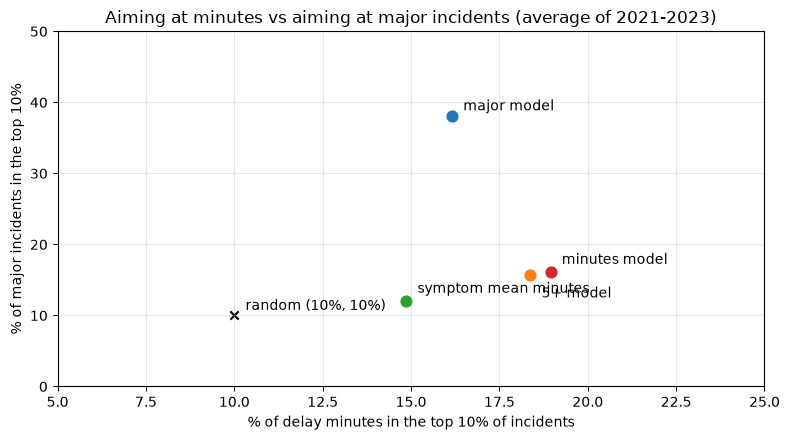

In [11]:
# Plot: what each ranking catches in its top 10%: delay minutes vs major incidents.
# Label offsets in points; the 5+ and minutes models sit close together.
label_offsets = {"5+ model": (8, -16), "minutes model": (8, 6), "symptom mean minutes": (8, 6)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, row in averages.iterrows():
    ax.scatter(100 * row["minutes caught (top 10%)"], 100 * row["major caught (top 10%)"], s=60)
    ax.annotate(name, (100 * row["minutes caught (top 10%)"], 100 * row["major caught (top 10%)"]),
                textcoords="offset points", xytext=label_offsets.get(name, (8, 4)))
ax.scatter(10, 10, marker="x", color="black")
ax.annotate("random (10%, 10%)", (10, 10), textcoords="offset points", xytext=(8, 4))
ax.set_xlim(5, 25)
ax.set_ylim(0, 50)
ax.set_xlabel("% of delay minutes in the top 10% of incidents")
ax.set_ylabel("% of major incidents in the top 10%")
ax.set_title("Aiming at minutes vs aiming at major incidents (average of 2021-2023)")
plt.tight_layout()
plt.show()

**Findings.**
* **A model aimed at minutes does only a little better on minutes.** In its top 10% it
  catches 18.9% of delay minutes, against 18.4% for the 5+ model and 16.2% for the
  major model. Random selection would catch 10%.
* **Minutes are hard to predict from what is known at report time.** The minutes
  model explains only about 7% of the deviance, and its rank correlation with the
  actual minutes is about 0.23. The symptom alone explains under 5%.
* **Aiming at minutes gives up the major incidents.** The minutes model and the 5+
  model put only about 15% of major incidents and safety responses in their top 10%
  (14.4-16.1%), against about 40% for the major model (38.1% and 39.6%).
* So the gain on minutes (about 3 points) costs more than half of the major incidents
  caught (about 22 points).

## 4. Answer

1. **Delay minutes is a usable but secondary metric.** Counted from the recorded delay
   it is a measurement, not an assumption, but it still gives many safety responses
   little or no weight.
2. **A model aimed at minutes does not catch many more of them.** At report time the
   data says little about how many minutes an incident will cost, so no ranking gets
   far beyond a fifth of the minutes in its top 10%.
3. **Recommendation.** Keep **safety responses and major incidents** as the target and
   headline: they are predictable (about 4x better than chance) and they are what the
   safety priority asks for. Report delay minutes as a **secondary** measure.

**Next.** A classification aimed at the delays themselves (for example the 5+ or 10+
threshold) can be added later as a separate view for operations, with the trade-off
above stated next to it.